In [1]:
import numpy as np
import seaborn as sns
from scipy.signal import correlate2d
from Cell2D import Cell2D, draw_array
from matplotlib.colors import LinearSegmentedColormap
from scipy.signal import correlate2d
from empiricaldist import Cdf
from utils import three_frame, number_frame, decorate, set_palette
import matplotlib.pyplot as plt

In [2]:
# make a custom color map
palette = sns.color_palette('muted')
colors = 'white', palette[1], palette[0]
cmap = LinearSegmentedColormap.from_list('cmap', colors)

#考虑到后面还需要结婚搬家之类的，参考一下老师的sugar模型，地图（房子）和agent单独做一个class

In [3]:
class Person():

    id = 0

    def __init__(self, loc, group):
        """
        group:
            1 = red / group A
            2 = blue / group B
        """

        # 给每个人一个独立 ID
        # 后面记录组合，和谁呆了一起，就很方便记录
        self.id = Person.id
        Person.id += 1

        # 当前住的位置
        self.loc = tuple(loc)

        # 保存这个人的原始 group
        self.group = group

        # 每个人独立随机一个 openness
        # 0.1, 0.2, ..., 0.9
        self.openness = np.random.randint(1, 10) / 10

In [4]:
def locs_where(condition):
    """Find cells where a logical array is True.

    condition: logical array

    returns: list of location tuples (identified by the row/column indices)
    """
    return list(zip(*np.nonzero(condition)))

class Schelling(Cell2D):
    """Represents a grid of Schelling agents."""

    options = dict(mode='same', boundary='wrap')

    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]], dtype=np.int8)

    def __init__(self, n, p):
        """Initializes the attributes.

        n: number of rows -- size of the grid
        p: threshold on the fraction of similar neighbors 满意度阈值
        """
        self.p = p
        # 0 is empty house, 1 is agent labelled red, 2 is agent labelled blue
        choices = np.array([0, 1, 2], dtype=np.int8)
        probs = [0.1, 0.45, 0.45]

        # randomly initialize a grid of houses of n by, occupied by two kinds of agents (red and blue)
        # in roughly equal numbers. About 10% of the houses are empty.
        # in [0, 1, 2], o has 10% to be chosen, 1 and 2 each has 45% to be chosen.
        self.array = np.random.choice(choices, (n, n), p=probs) # 这句已经随机生成了 0 / 1 / 2

        #我得知道上一个代码以及随机生成了0，1，2空房子的不同的group，现在得把每个人信息收集起来
        # Dictionary: key = location, for example (3, 5) value = Person object
        # empty cells will NOT be stored here

        self.people = {}

        # 遍历整个 grid，得到所有的person
        for row in range(n):
            for col in range(n):
                group = self.array[row, col] #一共就只有0，1，2
                # 0 是空房，所以不创建 Person
                if group != 0:
                    loc = (row, col) # 创建这个位置上的 Person
                    person = Person(loc, group)
                    self.people[loc] = person # 保存 Person


    def count_neighbors(self):
        """Surveys neighboring cells.

        returns: tuple of
            empty: True where cells are empty
            frac_red: fraction of red neighbors around each cell
            frac_blue: fraction of blue neighbors around each cell
            frac_same: fraction of neighbors with the same color
        """
        a = self.array

        # create three arrays that contain False/True (0/1) values
        # to later count the different type of neighbours separately
        empty = a==0
        red = a==1 #先把red和blue单独摘出来方便后面计算每个agent分别有多少个red和blue
        blue = a==2

        # correlate with the kernel, considering the 8 surronding neighbours
        # for agent labelled by red, count how many neighbours are also red agents
        # for agent labelled by blue, count how many neigbours are also blue neighbours
        num_red = correlate2d(red, self.kernel, **self.options)
        num_blue = correlate2d(blue, self.kernel, **self.options)
        
        # for each aget, count the total neighbours (no matter blue or red) it has
        num_neighbors = num_red + num_blue

        # compute fraction of similar neighbors 分别计算red和blue的领居占比
        # Some cells may have no occupied neighbours, so num_neighbors can be 0.
        # Ignore the temporary division warning here.
        with np.errstate(divide='ignore', invalid='ignore'):
            frac_red = num_red / num_neighbors 
            frac_blue = num_blue / num_neighbors

        # no neighbors is considered the same as no similar neighbors 如果周围领居的数为0，就把red和blue的设为0
        # (this is an arbitrary choice for a rare event)

        frac_red[num_neighbors == 0] = 0
        frac_blue[num_neighbors == 0] = 0

        # for each cell, fill the fraction of neighbors with the same color
        # wherever red is True, frac_same gets the corresponding element of frac_red.
        # where red is False, frac_same gets the corresponding element of frac_blue.
        # np.where(condition, value_if_true, value_if_false) 如果这个位置是 red，就用 frac_red；否则用 frac_blue。
        frac_same = np.where(red, frac_red, frac_blue)

        # where red is False could be either blue or empty
        # thus, one additional step:
        # for empty cells, frac_same is NaN
        # 如果是空房子，单独设置一下
        frac_same[empty] = np.nan

        # 先复制原来的 frac_same，保持相同的 grid 大小
        satisfaction = frac_same.copy()
        # 每个人使用自己的 openness 计算 satisfaction
        for loc, person in self.people.items():
            satisfaction[loc] = (frac_same[loc]+ (1 - frac_same[loc]) * person.openness)

        # 如果周围一个邻居都没有，不应该因为 openness 很高就得到很高的 satisfaction。
        # 所以我们仍然按照原模型的思路：no neighbours -> satisfaction = 0
        satisfaction[num_neighbors == 0] = 0

        # 同样的空房子不存在 agent，所以没有satisfaction
        satisfaction[empty] = np.nan

        return empty, frac_red, frac_blue, frac_same, satisfaction

    def segregation(self):
        """Computes the average fraction of similar neighbors.
        returns: fraction of similar neighbors, averaged over cells
        segregation 的含义，如果返回：0.72
        意思：平均而言，每个 agent 的邻居中约 72% 和自己同类型。
        """
        # For quantitative analysis of segregation
        _, _, _, frac_same, _ = self.count_neighbors()
        return np.nanmean(frac_same)

    def step(self):
        """Executes one time step.
        returns: fraction of similar neighbors, averaged over cells
        """
        a = self.array
        empty, _, _, frac_same, satisfaction = self.count_neighbors()

        # find the unhappy cells (ignore NaN in frac_same)
        with np.errstate(invalid='ignore'):
            unhappy = satisfaction < self.p # an agent will be unhappy if fewer than p of their neighbors are the same color.
        unhappy_locs = locs_where(unhappy) # return list of (row, column) index tuples to specify the unhappy location

        # find the empty cells: the list of (row, column) index tuples for empty location
        empty_locs = locs_where(empty)

        # shuffle the unhappy cells
        #因为不希望：永远按照 row 0 → row 1 → row 2 的固定顺序搬家。这样模型会产生人为的方向性 bias。随机 shuffle 更合理
        if len(unhappy_locs):
            np.random.shuffle(unhappy_locs)

        # for each unhappy cell, choose a random destination
        num_empty = np.sum(empty)

        for source in unhappy_locs:
            i = np.random.randint(num_empty) #随机得到一个空房子
            dest = empty_locs[i] #准备搬到这个空房子

            # 找到 source 上的 Person
            # 同时删除旧 location 的 dictionary 记录
            # pop 从字典里“取出这个值，并且把这一项删除”
            person = self.people.pop(source)

            # move
            a[dest] = person.group # unhappy agent moves to the empty location, state value updates from 0 to 1 or 2 人先过去
            a[source] = 0 # the unhappy agent's location becomes empty after it moves away 老房子没人了
            person.loc = tuple(dest) # update person's location in class

            self.people[dest] = person # 更新当前class中的people字典
            empty_locs[i] = source # update the empty location list to include the location of unhappy agent that just moved away 把老房子加入空房子列表

            # check that the number of empty cells remains the same
            num_empty2 = np.sum(a==0)
            assert num_empty == num_empty2

        # return the average fraction of similar neighbors
        return np.nanmean(frac_same)

    def draw(self):
        """Draws the cells."""
        return draw_array(self.array, cmap=cmap, vmax=2)

接下来就是住房的问题，后面如果出现结婚或则组合的情况，那么这个这个房子对附近邻居产生的影响是根据这个房子里住的人住了哪些人

In [114]:
grid = Schelling(n=100, p=0.4)

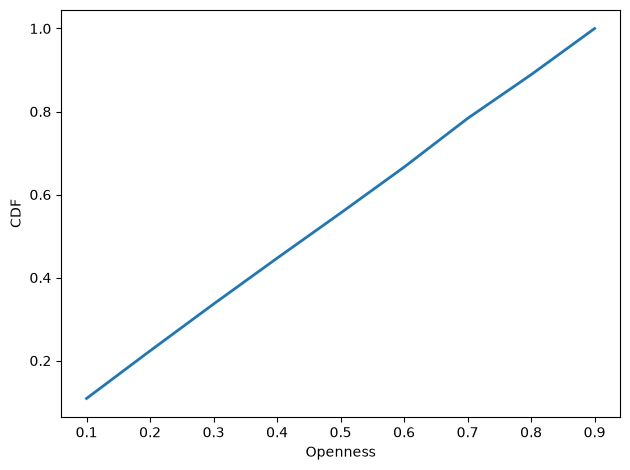

In [115]:
# Check the initial distribution of openness
cdf = Cdf.from_seq(
    person.openness
    for person in grid.people.values()
)

cdf.plot()

decorate(
    xlabel='Openness',
    ylabel='CDF'
)

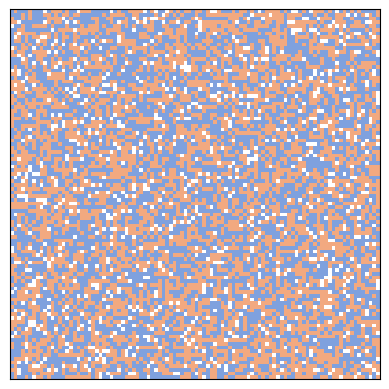

In [116]:
grid.draw()

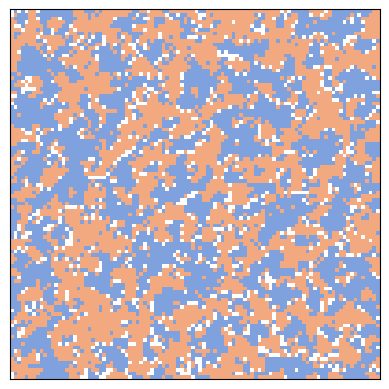

In [117]:
grid = Schelling(n=100, p=0.76)
grid.animate(frames=10, interval=0.1) #animate这个function里面有step会自己跳动

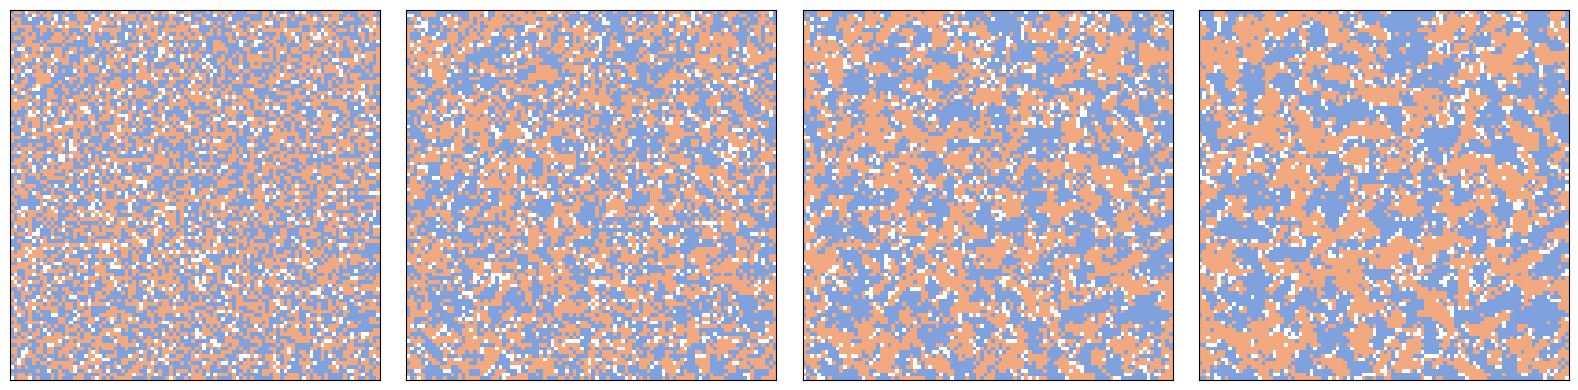

In [118]:
grid = Schelling(n=100, p=0.76)
# three_frame(grid, [0, 2, 8]) #step0,0+2,0+2+8
number_frame(grid,[0,2,3,5],4)

# 图 1：p=0.2 ～ 0.9的整体趋势
这张图主要用来观察不同满意度阈值p对segregation的整体影响。可以看到，p从0.2增加到0.8时，最终segregation总体上逐渐提高；但当p=0.9时，segregation反而下降，而且曲线持续波动。这说明segregation并不是随着p无限增加，而是在较高p附近达到峰值后开始下降。一个可能原因是，当满意度要求过高时，大量Agent很难找到满足条件的位置，因此不断随机搬家，系统反而难以稳定。

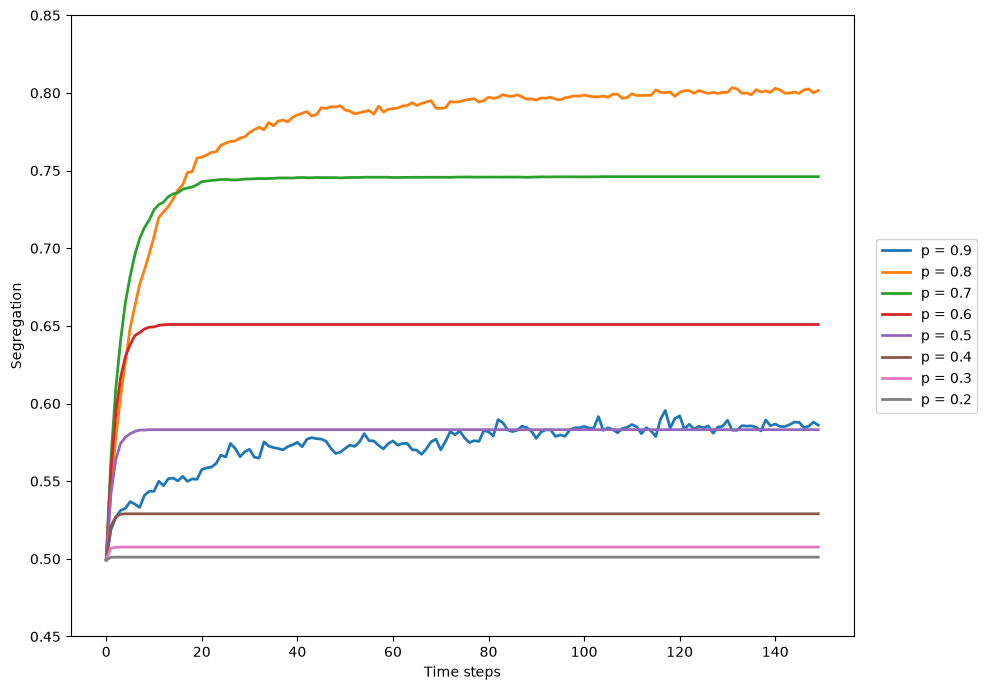

In [119]:
plt.figure(figsize=(10, 7))

for i, p in enumerate([0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2]):

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(
        segs,
        label='p = %.1f' % p
    )

decorate(
    xlabel='Time steps',
    ylabel='Segregation', #Segregation 表示一个 Agent 周围的已占用邻居中，有多少比例和自己属于同一个 group，然后再对所有 Agent 取平均。
    ylim=[0.45, 0.85]
)

# 把 legend 放到图的右边外面
plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 2：p=0.2 ～ 0.7的稳定速度
这张图主要用来看模型大约需要多少timestep才能稳定。低p情况，例如p=0.2 ～ 0.4，几乎马上稳定，因为大多数Agent一开始已经满足要求。随着p增加，模型需要更多timestep才能稳定，例如 \(p=0.6\) 和 \(p=0.7\) 大约需要15–30个timestep。总体上说明：在正常范围内，满意度要求越高，系统达到稳定状态所需要的时间越长。

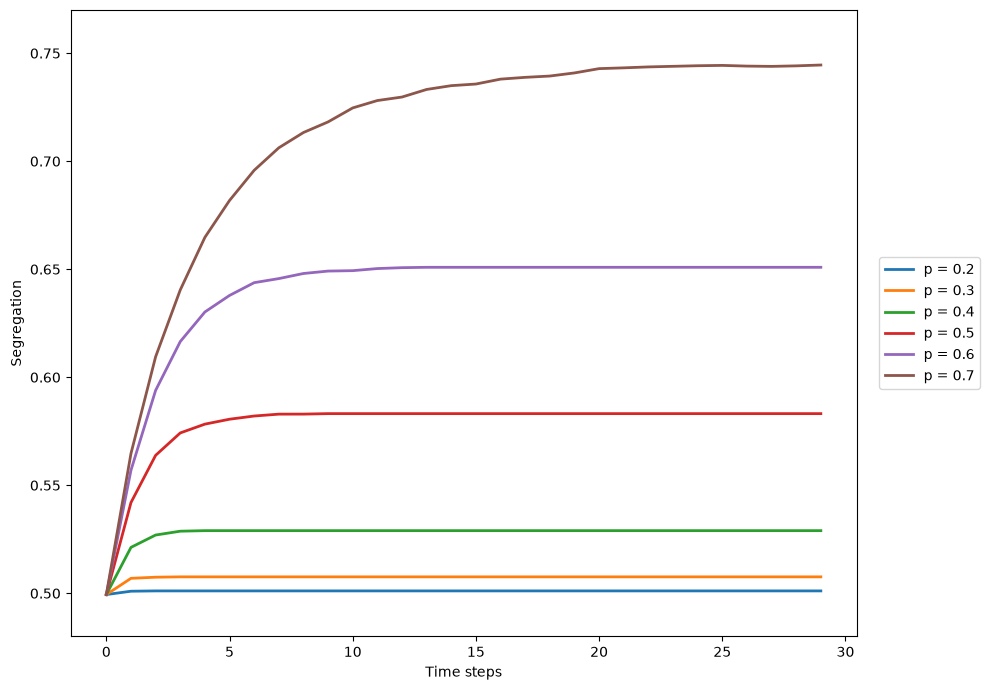

In [120]:
plt.figure(figsize=(10, 7))

for p in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(30)]

    plt.plot(segs, label='p = %.1f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.48, 0.77)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 3：p=0.7 ～ 0.9的高满意度区域
这张图把高p区域进一步放大。可以看到p=0.7到0.8时segregation较高，而且最后能够接近稳定；但是从大约p=0.85开始，最终segregation明显下降，同时曲线波动增加。到p=0.9时这种现象最明显。因此，高满意度要求并不一定导致更严重的segregation，反而可能使Agent长时间持续移动，导致系统难以达到equilibrium。

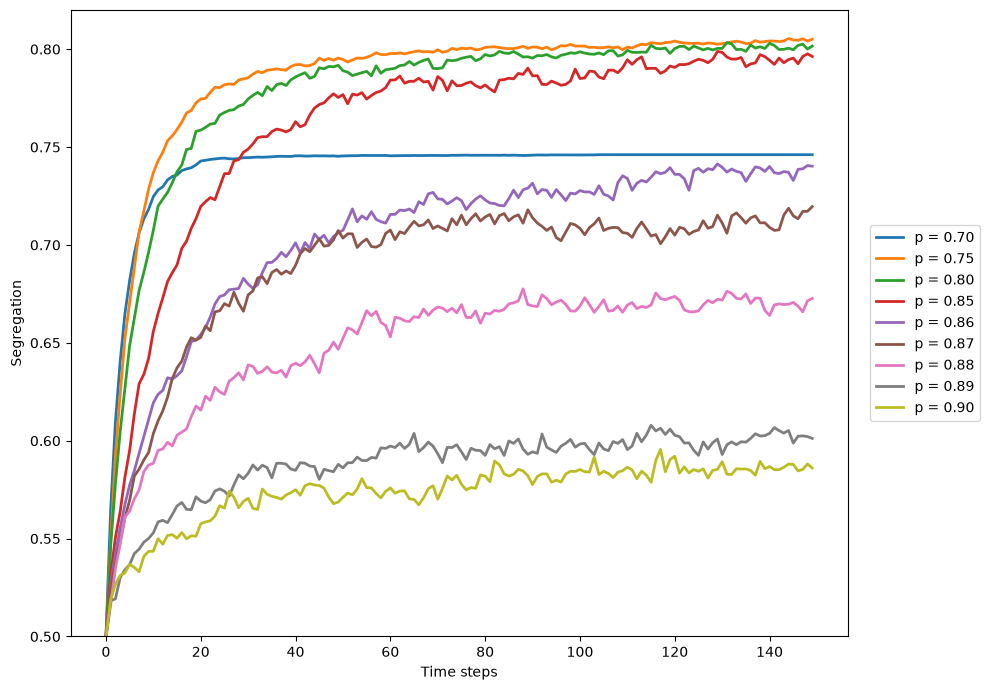

In [121]:
plt.figure(figsize=(10, 7))

for p in [0.7, 0.75, 0.8, 0.85, 0.86, 0.87, 0.88, 0.89, 0.9]:

    np.random.seed(17)

    grid = Schelling(n=100, p=p)

    segs = [grid.step() for step in range(150)]

    plt.plot(segs, label='p = %.2f' % p)

plt.xlabel('Time steps')
plt.ylabel('Segregation')
plt.ylim(0.50, 0.82)

plt.legend(
    bbox_to_anchor=(1.02, 0.5),
    loc='center left'
)

plt.tight_layout()
plt.show()

# 图 4：p=0.75 ～ 0.80的峰值搜索
目前可以认为，在当前模型参数下，segregation的峰值区域大约位于p=0.76 ～ 0.77。这只是当前实验得到的数值峰值，之后还可以增加random seeds来确认它是否稳定。

p = 0.75, mean segregation = 0.8065
p = 0.76, mean segregation = 0.8223
p = 0.77, mean segregation = 0.8216
p = 0.78, mean segregation = 0.8070
p = 0.79, mean segregation = 0.8086
p = 0.80, mean segregation = 0.8086

Peak p = 0.76
Maximum segregation = 0.8223425000990587


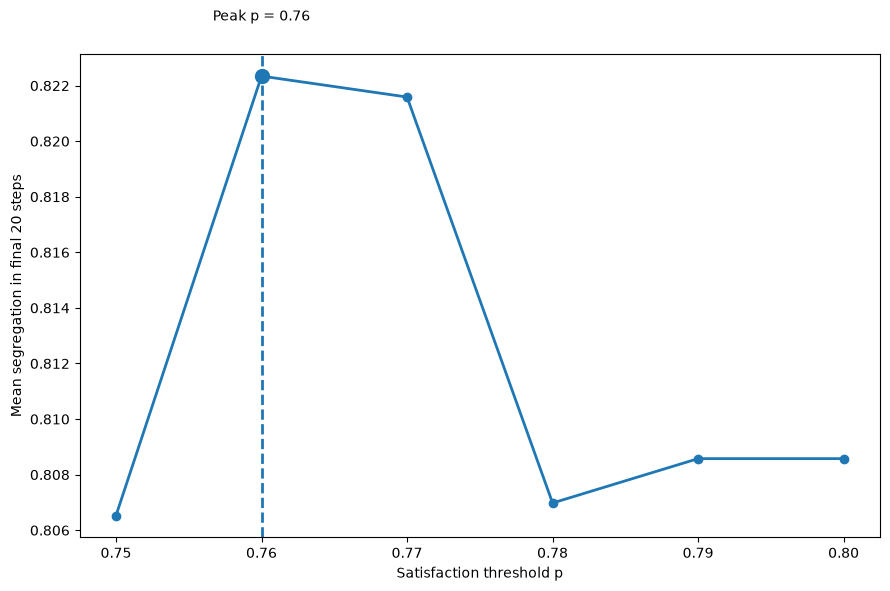

In [122]:
# Test p from 0.75 to 0.80
p_values = np.round(np.arange(0.75, 0.801, 0.01), 2)

seeds = range(5)
n_steps = 200
final_window = 20

mean_segs = []

for p in p_values:

    results = []

    for seed in seeds:

        np.random.seed(seed)

        grid = Schelling(n=100, p=p)

        segs = []

        for step in range(n_steps):
            grid.step()
            segs.append(grid.segregation())

        # Average segregation of the final 20 steps
        results.append(np.mean(segs[-final_window:]))

    # Average result from all seeds
    mean_segs.append(np.mean(results))

    print(f"p = {p:.2f}, "f"mean segregation = {np.mean(results):.4f}")

# Find the maximum
peak_index = np.argmax(mean_segs)

peak_p = p_values[peak_index]
peak_seg = mean_segs[peak_index]

print("\nPeak p =", peak_p)
print("Maximum segregation =", peak_seg)

# Plot
plt.figure(figsize=(9, 6))

plt.plot(p_values, mean_segs, marker='o', linewidth=2)

# Mark the peak
plt.scatter(peak_p, peak_seg, s=100)

plt.axvline(peak_p, linestyle='--')

plt.text(peak_p, peak_seg + 0.002, f'Peak p = {peak_p:.2f}', ha='center')

plt.xlabel('Satisfaction threshold p')
plt.ylabel('Mean segregation in final 20 steps')

plt.xticks(p_values)

plt.tight_layout()
plt.show()

## Milestone 3 & 4：家庭配对 (Household Formation)

在上面 Schelling 模型的基础上，加入计划书里 Milestone 3（同群体配对成家 AA/BB）
和 Milestone 4（跨群体配对 AB）的逻辑，尽量不改动上面已经写好、跑过实验的代码。

设计思路：
- 新增一个 `Household` 类，代表"住在一间房子里的家庭"，可以是 1 个人（单人户），
  也可以是配对之后的 2 个人（AA / BB / AB）。`Person` 还是原来那个 `Person`，
  一个人配对之后并不会消失，只是和另一个人共享同一个 `Household`，这样原始的
  `group`（属于计划书里说的 original_group）信息不会丢。
- `ExtendedSchelling` 直接**继承**上面的 `Schelling`：`__init__` 先调用父类，
  生成和原来完全一样的网格、`self.people`，然后把每个人包一层 `Household`。
- 每一步 (`step()`) 严格按照计划书 P10 的固定顺序执行：
  满意度 → 搬家 → 重新评估 → 更新接触时长 → 配对匹配 → 家庭合并 → 统计。
- 满意度 (P8) 用一张邻居权重表：同类邻居权重=1，跨类邻居权重=w_h（AB 家庭
  固定用 q=0.70），"混合家庭"邻居（对方是 AB）权重=(1+w_h)/2。
- 配对概率 (P9)：同群体配对成功率 = m；跨群体 (AB) 配对成功率 = m × min(w_i, w_j)，
  也就是双方 openness 越低，越不容易跨群体成家。
- 接触时长 d(i,j) 每一步都重新统计一次：只要两户不再相邻，或者其中一户已经和
  别人配对了，这一对的计时就自动消失，不需要手动清零。

⚠️ 下面几个地方是我自己根据计划书拿的主意，建议和计划书原文再对一下：
1. "满意"直接复用了上面 `Schelling` 已经在用的阈值 `p`（`H_h >= p`）。
2. AB 家庭自己的 openness 固定用 `q`，而不是取两个成员 openness 的平均值。
3. "同边" 的判定：A 单人户和 AA 户算同一边，B 单人户和 BB 户算另一边，
   AB 户不属于任何一边，邻居是 AB 户时永远用专门的 (1+w_h)/2 权重。
4. 配对合并后，`self.people` 就不再维护了（它是"一间房一个人"的假设，配对后
   不再成立），所有统计都改用 `self.households` / `self.by_id`。

下面除了正确性检查以外，一共有 5 张图：网格状态对比（图5）、家庭结构随时间变化的
堆叠图（图6）、空房率/满意度随时间变化（图7）、配对概率 m 的影响（图8，含最终结构
对比柱状图）、接触时长阈值 L 对配对速度的影响（图9）。

还没做的：计划书 P12 里提到的 origin-group exposure（a_h）和 AB 局部聚集度这两个
指标还没加进 `_metrics()`，等这版逻辑确认没问题了可以再加。

In [5]:
class Household:
    """住在同一间房子里的家庭：可以是单人户，也可以是配对后的两人户 (AA/BB/AB)。

    和 Person 分开存储的原因：配对之后原来的两个 Person 对象都还在，只是共享
    同一个 Household，这样原始的 group 信息（原来是 A 还是 B）永远不会丢，即使
    组成了 AB 家庭。
    """

    _next_id = 0

    # household 的类型编码，直接存进 self.array 里（1/2 和原来 Schelling 的编码保持一致）
    EMPTY, A, B, AA, BB, AB = 0, 1, 2, 3, 4, 5

    def __init__(self, position, members, can_pair=True, q=0.70):
        self.id = Household._next_id
        Household._next_id += 1
        self.position = tuple(position)
        self.members = list(members)      # 1 个或 2 个 Person
        self.can_pair = can_pair          # 配对成功一次之后永久变成 False
        self.q = q
        self.H = 0.0                      # 本轮 satisfaction，由 count_neighbors_ext() 填
        self.satisfied = False

    @property
    def type_code(self):
        """1=A单人户, 2=B单人户, 3=AA, 4=BB, 5=AB（混合家庭）。"""
        if len(self.members) == 1:
            return self.members[0].group
        g0, g1 = self.members[0].group, self.members[1].group
        if g0 == 1 and g1 == 1:
            return Household.AA
        if g0 == 2 and g1 == 2:
            return Household.BB
        return Household.AB

    @property
    def side(self):
        """这个 household 站在哪一边：'A' / 'B' / 'AB'（混合家庭没有固定边）。"""
        t = self.type_code
        if t in (Household.A, Household.AA):
            return 'A'
        if t in (Household.B, Household.BB):
            return 'B'
        return 'AB'

    @property
    def effective_openness(self):
        """w_h。AB 家庭固定用 q（计划书里专门给 AB 一侧定的参数），
        其余情况取家庭成员 openness 的平均值（单人户就是自己的 openness）。"""
        if self.type_code == Household.AB:
            return self.q
        if len(self.members) == 1:
            return self.members[0].openness
        return 0.5 * (self.members[0].openness + self.members[1].openness)

In [6]:
# 给 6 种状态 (empty, A, B, AA, BB, AB) 单独做一个配色，和上面单人版的 cmap 区分开。
# 特意把 A/AA 设计成同一个色系的浅/深两种橙色，B/BB 设计成同一个色系的浅/深两种蓝色——
# 因为在 count_neighbors_ext() 里，A 和 AA 本来就被当成"同一边"（邻居权重=1），
# 用同色系只是深浅不同，看图的时候更容易看出真实的聚集情况，而不会被 6 种毫不相关的
# 颜色拆得很碎。AB（混合家庭）单独用一个中性紫色，不属于任何一边。
from matplotlib.colors import ListedColormap
cmap_ext = ListedColormap(['white', '#f4a261', '#457b9d', '#9c3d17', '#1d3557', '#6a4c93'])

In [7]:
class ExtendedSchelling(Schelling):
    """在 Schelling 基础上加入 Milestone 3（同群体配对 AA/BB）
    和 Milestone 4（跨群体配对 AB）。

    直接继承 Schelling：__init__ 先调用父类生成和原来完全一样的
    0/1/2 网格 + self.people，然后把每个人包装成一个单人 household。
    """

    # 8 个 Moore 邻居的偏移量，用来判断两个 household 是否相邻（算 contact-time 用）
    _NEIGHBOR_OFFSETS = [(-1, -1), (-1, 0), (-1, 1),
                         (0, -1),           (0, 1),
                         (1, -1),  (1, 0),  (1, 1)]

    def __init__(self, n, p, m=0.05, L=3, q=0.70):
        """
        n, p: 和父类 Schelling 完全一样（网格大小、满意度阈值）
        m: 每一步，一对符合条件的家庭配对成功的基础概率
        L: 配对之前两户至少要连续相邻多少步（contact-time 门槛）
        q: AB 家庭固定使用的 openness / 邻居权重参数
        """
        super().__init__(n, p)   # 完全复用父类：self.array, self.people
        self.n = n
        self.m = m
        self.L = L
        self.q = q

        # 把父类生成的每个 Person 包装成一个单人 household
        self.households = {}
        self.by_id = {}
        for loc, person in self.people.items():
            h = Household(loc, [person], can_pair=True, q=self.q)
            self.households[loc] = h
            self.by_id[h.id] = h
            # array 本来就是 1/2 (person.group)，单人户的 type_code 也是 1/2，不用改

        self.contact = {}     # frozenset({household_id1, household_id2}) -> 连续相邻步数
        self.last_metrics = {}

    # ---------- P8：加权满意度（同类=1，跨类=w_h/q，混合家庭邻居=(1+w_h)/2） ----------
    def count_neighbors_ext(self):
        a = self.array
        maskA = (a == Household.A) | (a == Household.AA)
        maskB = (a == Household.B) | (a == Household.BB)
        maskAB = (a == Household.AB)

        numA = correlate2d(maskA, self.kernel, **self.options)
        numB = correlate2d(maskB, self.kernel, **self.options)
        numAB = correlate2d(maskAB, self.kernel, **self.options)

        sat_arr = np.full(a.shape, np.nan)

        for pos, h in self.households.items():
            w = h.effective_openness
            if h.side == 'A':
                same, cross, ab = numA[pos], numB[pos], numAB[pos]
            elif h.side == 'B':
                same, cross, ab = numB[pos], numA[pos], numAB[pos]
            else:  # AB 家庭
                same, cross, ab = numAB[pos], numA[pos] + numB[pos], 0

            total = same + cross + ab
            if total == 0:
                H = 0.0
            elif h.side == 'AB':
                H = (same * 1.0 + cross * w) / total
            else:
                H = (same * 1.0 + cross * w + ab * ((1.0 + w) / 2.0)) / total

            h.H = H
            h.satisfied = H >= self.p
            sat_arr[pos] = H

        return sat_arr

    # ---------- 第2步：搬家（逻辑和父类 step() 里的搬家部分一样，只是作用在 household 上） ----------
    def _relocate_unhappy(self, sat_arr):
        empty_locs = locs_where(self.array == 0)
        unhappy_positions = [pos for pos, h in self.households.items() if not h.satisfied]
        np.random.shuffle(unhappy_positions)

        num_empty = len(empty_locs)
        moves = 0
        for source in unhappy_positions:
            if num_empty == 0:
                break
            i = np.random.randint(num_empty)
            dest = empty_locs[i]

            h = self.households.pop(source)
            self.array[dest] = h.type_code
            self.array[source] = 0
            h.position = tuple(dest)
            self.households[dest] = h

            empty_locs[i] = source
            moves += 1

            # 和父类一样，做一次守恒检查
            assert num_empty == np.sum(self.array == 0)

        return moves

    # ---------- 第4步：接触时长 d(i,j)，每一步都重新统计一遍 ----------
    def _update_contact_time(self):
        n = self.n
        new_contact = {}
        singles = [h for h in self.households.values()
                   if len(h.members) == 1 and h.can_pair]

        for h in singles:
            r, c = h.position
            for dr, dc in self._NEIGHBOR_OFFSETS:
                nr, nc = (r + dr) % n, (c + dc) % n
                other = self.households.get((nr, nc))
                if other is None or other.id <= h.id:
                    continue   # 空房，或者这一对已经数过了
                if len(other.members) != 1 or not other.can_pair:
                    continue
                key = frozenset((h.id, other.id))
                new_contact[key] = self.contact.get(key, 0) + 1

        self.contact = new_contact

    # ---------- 第5+6步：配对匹配 + 合并成新家庭 ----------
    def _match_and_merge(self):
        eligible = [key for key, cnt in self.contact.items() if cnt >= self.L]
        np.random.shuffle(eligible)

        matched = set()
        pairs_formed = 0

        for key in eligible:
            id1, id2 = tuple(key)
            if id1 in matched or id2 in matched:
                continue
            h1, h2 = self.by_id.get(id1), self.by_id.get(id2)
            if h1 is None or h2 is None or not (h1.can_pair and h2.can_pair):
                continue
            if not (h1.satisfied and h2.satisfied):
                continue

            p1, p2 = h1.members[0], h2.members[0]
            if p1.group == p2.group:
                prob = self.m                                   # P_same
            else:
                prob = self.m * min(p1.openness, p2.openness)   # P_mixed

            if np.random.random() < prob:
                matched.add(id1)
                matched.add(id2)
                self._merge(h1, h2)
                pairs_formed += 1

        return pairs_formed

    def _merge(self, h1, h2):
        keep_pos = h1.position if np.random.random() < 0.5 else h2.position
        other_pos = h2.position if keep_pos == h1.position else h1.position

        new_h = Household(keep_pos, h1.members + h2.members, can_pair=False, q=self.q)

        del self.households[h1.position]
        del self.households[h2.position]
        del self.by_id[h1.id]
        del self.by_id[h2.id]

        self.households[keep_pos] = new_h
        self.by_id[new_h.id] = new_h

        self.array[keep_pos] = new_h.type_code
        self.array[other_pos] = 0
        # 注意：配对成家之后，self.people 就不再维护了（它是"一间房一个人"的假设，
        # 配对之后不再成立），后面所有统计都改用 self.households / self.by_id。

    # ---------- 第7步：统计指标 ----------
    def _metrics(self, moves, pairs_formed):
        hs = list(self.households.values())
        n_h = len(hs)
        counts = {'A': 0, 'B': 0, 'AA': 0, 'BB': 0, 'AB': 0}
        code_to_name = {Household.A: 'A', Household.B: 'B', Household.AA: 'AA',
                         Household.BB: 'BB', Household.AB: 'AB'}
        for h in hs:
            counts[code_to_name[h.type_code]] += 1

        n_persons = sum(len(h.members) for h in hs)
        n_cells = self.n * self.n
        n_satisfied = sum(1 for h in hs if h.satisfied)

        return {
            'n_households': n_h,
            'counts': counts,
            'mixed_family_share': counts['AB'] / n_h if n_h else 0.0,
            'mixed_family_population_share': (2 * counts['AB']) / n_persons if n_persons else 0.0,
            'satisfied_share': n_satisfied / n_h if n_h else 0.0,
            'vacancy_rate': (n_cells - n_h) / n_cells,
            'moves_this_step': moves,
            'pairs_formed_this_step': pairs_formed,
            'n_persons': n_persons,
        }

    def step(self):
        """严格按照计划书 P10 的固定顺序：
        满意度 -> 搬家 -> 重新评估 -> 更新接触时长 -> 配对匹配 -> 家庭合并 -> 统计。
        """
        sat_arr = self.count_neighbors_ext()
        moves = self._relocate_unhappy(sat_arr)
        self.count_neighbors_ext()
        self._update_contact_time()
        pairs_formed = self._match_and_merge()
        self.count_neighbors_ext()   # 合并之后再刷新一次，统计用的是最新状态
        metrics = self._metrics(moves, pairs_formed)
        self.last_metrics = metrics
        return metrics

    def draw(self):
        return draw_array(self.array, cmap=cmap_ext, vmin=0, vmax=5)

### 快速验证：人数 / 家庭数是否守恒，配对逻辑有没有明显 bug

和上面父类 `step()` 里那个 `assert num_empty == num_empty2` 一样的思路，这里多加几条
检查：总人数不会变、家庭数每配对成功一次刚好减 1、没有家庭会被配对两次。

In [8]:
np.random.seed(0)
grid_ext = ExtendedSchelling(n=40, p=0.4, m=0.10, L=3, q=0.70)

n0_persons = sum(len(h.members) for h in grid_ext.households.values())
n0_households = len(grid_ext.households)

total_pairs = 0
for _ in range(80):
    m_out = grid_ext.step()
    total_pairs += m_out['pairs_formed_this_step']

n1_persons = sum(len(h.members) for h in grid_ext.households.values())
n1_households = len(grid_ext.households)

# 检查1：总人数不变
assert n1_persons == n0_persons, "人数没有守恒！"

# 检查2：家庭数减少量 == 配对成功次数（配对一次两户变一户）
assert n0_households - n1_households == total_pairs, "家庭数变化量和配对次数对不上！"

# 检查3：没有家庭被配对两次（合并后的家庭 can_pair 必须永远是 False）
for h in grid_ext.households.values():
    if len(h.members) == 2:
        assert h.can_pair == False, f"家庭 {h.id} 已经配对过，can_pair 却还是 True！"

print(f"人数守恒：{n0_persons} -> {n1_persons}")
print(f"家庭数：{n0_households} -> {n1_households}，80 步里一共配对成功 {total_pairs} 次")
print(f"最后一步统计：{m_out}")
print("全部检查通过")

人数守恒：1444 -> 1444
家庭数：1444 -> 781，80 步里一共配对成功 663 次
最后一步统计：{'n_households': 781, 'counts': {'A': 59, 'B': 59, 'AA': 244, 'BB': 245, 'AB': 174}, 'mixed_family_share': 0.22279129321382843, 'mixed_family_population_share': 0.2409972299168975, 'satisfied_share': 0.998719590268886, 'vacancy_rate': 0.511875, 'moves_this_step': 0, 'pairs_formed_this_step': 1, 'n_persons': 1444}
全部检查通过


# 图 5：三个时间点的网格状态对比

用改进过的配色（同一边深浅两色）重新看一下网格从初始状态到配对开始大量发生之后
是什么样子。`number_frame` 的参数是"每一帧之间再多跑多少步"，不是绝对时间点，
所以 `[0, 30, 90]` 对应的实际时间点是 t=0、t=30、t=120。

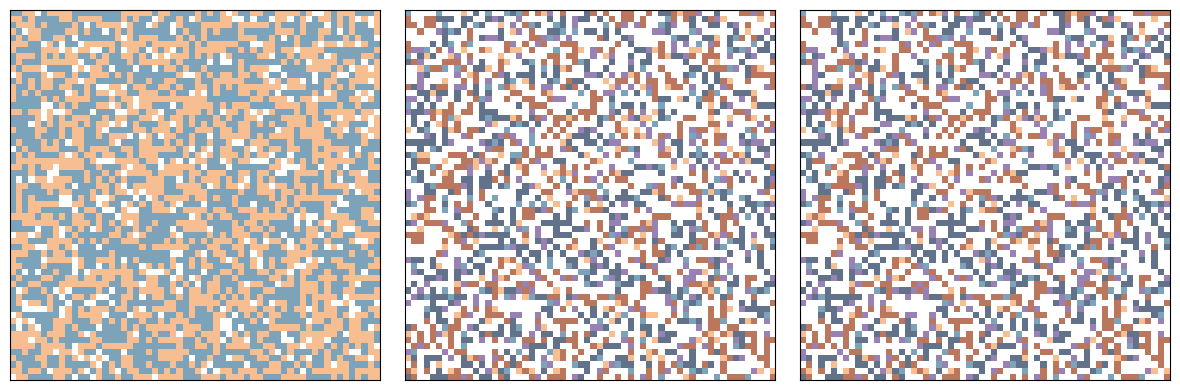

In [9]:
grid_demo = ExtendedSchelling(n=60, p=0.6, m=0.08, L=3, q=0.70)
number_frame(grid_demo, [0, 30, 90], 3)

# 图 6：家庭结构随时间的变化

跑一次模拟，把每一步的"空房 / A单人户 / B单人户 / AA / BB / AB"数量都记下来，
看整个网格是怎么从"全是单人户"逐渐变成"配对家庭为主"的。

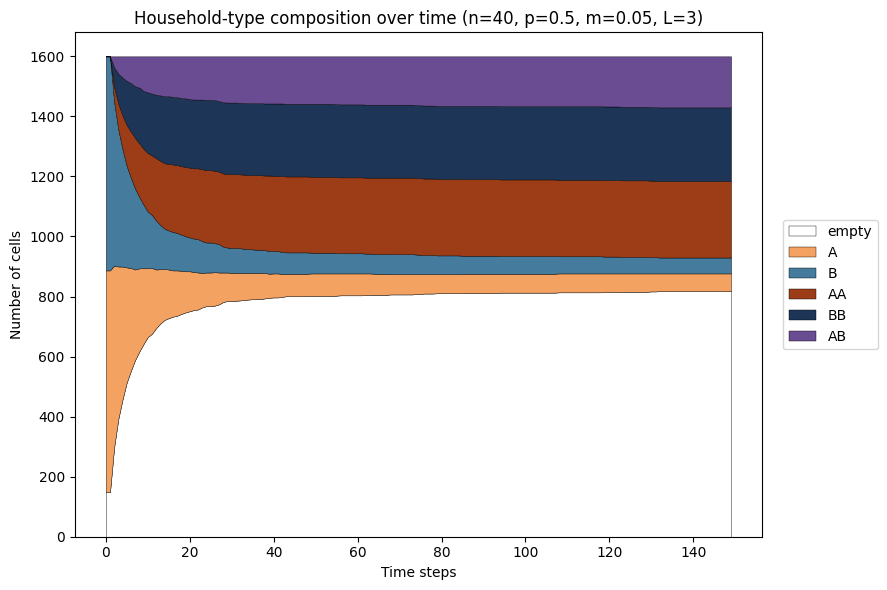

In [10]:
np.random.seed(11)
grid_comp = ExtendedSchelling(n=40, p=0.5, m=0.05, L=3, q=0.70)

n_steps_comp = 150
order = ['empty', 'A', 'B', 'AA', 'BB', 'AB']
history = {k: [] for k in order}
n_cells = grid_comp.n * grid_comp.n

for t in range(n_steps_comp):
    out = grid_comp.step()
    counts = out['counts']
    history['empty'].append(n_cells - out['n_households'])
    for k in ('A', 'B', 'AA', 'BB', 'AB'):
        history[k].append(counts[k])

plt.figure(figsize=(9, 6))
colors_stack = ['white', '#f4a261', '#457b9d', '#9c3d17', '#1d3557', '#6a4c93']
plt.stackplot(range(n_steps_comp), [history[k] for k in order],
              labels=order, colors=colors_stack, edgecolor='black', linewidth=0.3)

decorate(title='Household-type composition over time (n=40, p=0.5, m=0.05, L=3)',
         xlabel='Time steps',
         ylabel='Number of cells')

# 图例放到图外面右边，和上面 p 值扫描那张图一样的做法，避免挡住堆叠图本身
plt.legend(bbox_to_anchor=(1.02, 0.5), loc='center left')
plt.tight_layout()

# 图 7：空房率与满意家庭占比随时间变化

配对成功会腾出空房，所以空房率应该会随着配对不断上升；同时因为满意度公式对跨类邻居
也给了部分权重（不是非黑即白），满意家庭的占比应该会比较快地趋近于 1。

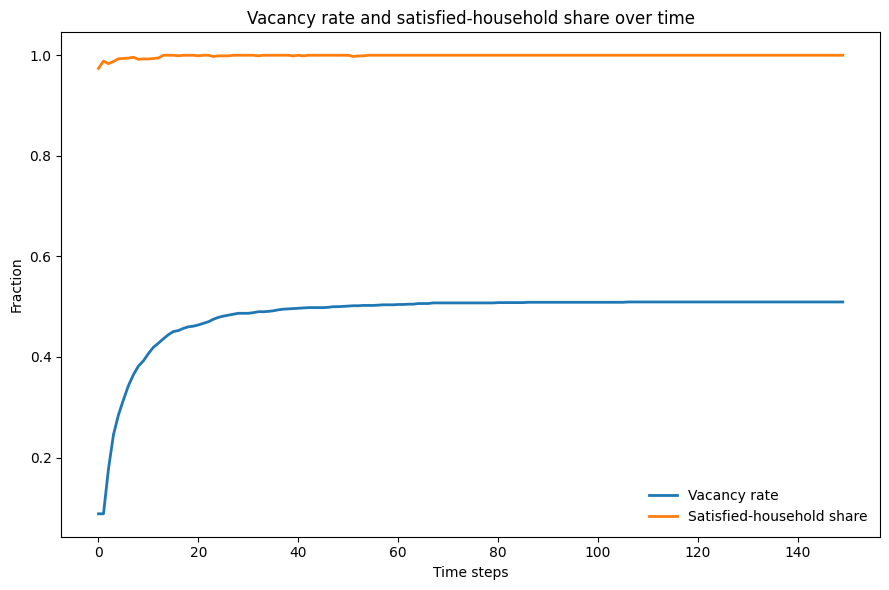

In [11]:
np.random.seed(12)
grid_dyn = ExtendedSchelling(n=40, p=0.5, m=0.05, L=3, q=0.70)

n_steps_dyn = 150
vacancy_trace = []
satisfied_trace = []

for t in range(n_steps_dyn):
    out = grid_dyn.step()
    vacancy_trace.append(out['vacancy_rate'])
    satisfied_trace.append(out['satisfied_share'])

plt.figure(figsize=(9, 6))
plt.plot(vacancy_trace, label='Vacancy rate')
plt.plot(satisfied_trace, label='Satisfied-household share')

decorate(title='Vacancy rate and satisfied-household share over time',
         xlabel='Time steps',
         ylabel='Fraction')

# 图 8：配对概率 m 对家庭结构的影响

对照计划书里给的三个候选值 m ∈ {0.02, 0.05, 0.10}，每个值跑 10 个随机种子、200 步，
看混合家庭 (AB) 占比随时间的变化趋势，以及 200 步之后最终的家庭结构分布。

m=0.02: 最终 (第200步) 平均混合家庭占比 = 0.214, 平均最终家庭结构 = {'A': np.float64(64.5), 'B': np.float64(69.3), 'AA': np.float64(244.3), 'BB': np.float64(241.1), 'AB': np.float64(169.0)}


m=0.05: 最终 (第200步) 平均混合家庭占比 = 0.225, 平均最终家庭结构 = {'A': np.float64(57.2), 'B': np.float64(57.6), 'AA': np.float64(244.7), 'BB': np.float64(243.7), 'AB': np.float64(175.5)}


m=0.10: 最终 (第200步) 平均混合家庭占比 = 0.232, 平均最终家庭结构 = {'A': np.float64(56.7), 'B': np.float64(55.9), 'AA': np.float64(242.5), 'BB': np.float64(242.1), 'AB': np.float64(180.4)}


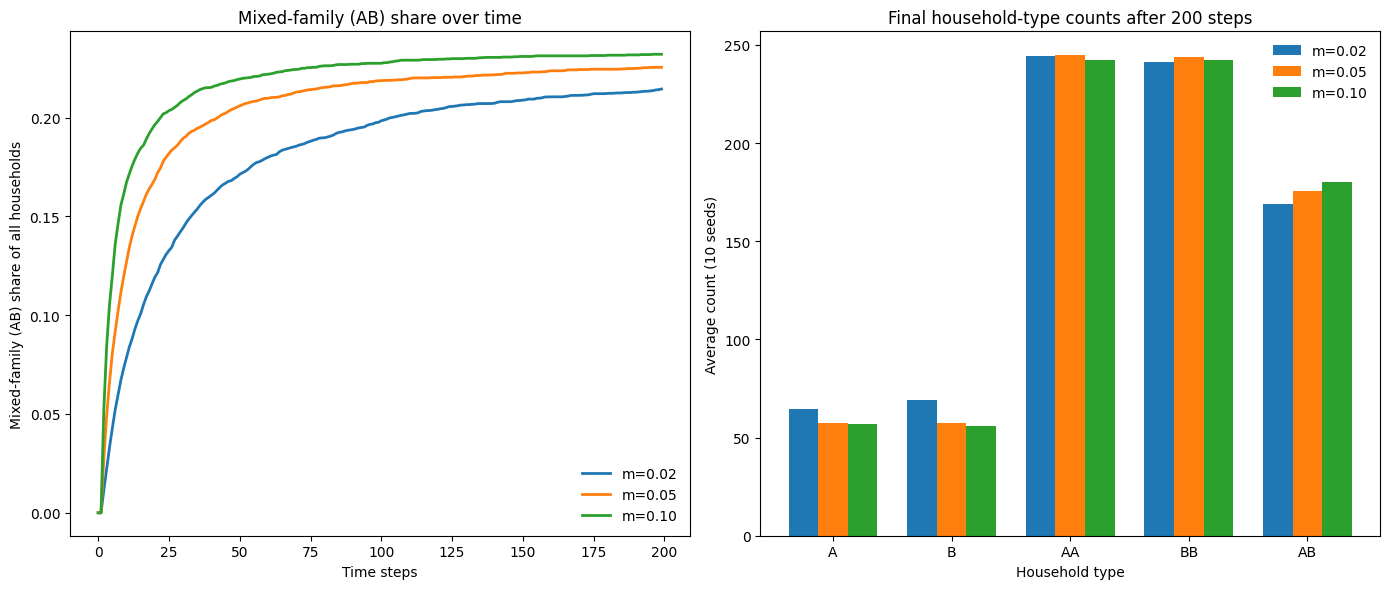

In [12]:
m_values = [0.02, 0.05, 0.10]
seeds = range(10)
n_steps = 200
household_types = ['A', 'B', 'AA', 'BB', 'AB']

mixed_share_curves = {}
final_counts_by_m = {}   # m -> dict of type -> average final count (across seeds)

for m in m_values:
    all_runs = []
    all_final_counts = []
    for seed in seeds:
        np.random.seed(seed)
        g = ExtendedSchelling(n=40, p=0.4, m=m, L=3, q=0.70)
        curve = []
        for t in range(n_steps):
            out = g.step()
            curve.append(out['mixed_family_share'])
        all_runs.append(curve)
        all_final_counts.append(out['counts'])
    mixed_share_curves[m] = np.mean(all_runs, axis=0)
    final_counts_by_m[m] = {t: np.mean([c[t] for c in all_final_counts]) for t in household_types}
    print(f"m={m:.2f}: 最终 (第{n_steps}步) 平均混合家庭占比 = {mixed_share_curves[m][-1]:.3f}, "
          f"平均最终家庭结构 = {final_counts_by_m[m]}")

# 左图：混合家庭占比随时间变化 (原来那张)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

plt.sca(axes[0])
for m in m_values:
    plt.plot(mixed_share_curves[m], label=f"m={m:.2f}")
decorate(title='Mixed-family (AB) share over time',
         xlabel='Time steps',
         ylabel='Mixed-family (AB) share of all households')

# 右图：200 步之后，三种 m 各自最终的家庭结构分布（分组柱状图）
plt.sca(axes[1])
x = np.arange(len(household_types))
width = 0.25
colors_bar = ['#f4a261', '#457b9d', '#9c3d17', '#1d3557', '#6a4c93']
for i, m in enumerate(m_values):
    values = [final_counts_by_m[m][t] for t in household_types]
    plt.bar(x + (i - 1) * width, values, width, label=f"m={m:.2f}")
plt.xticks(x, household_types)
decorate(title=f'Final household-type counts after {n_steps} steps',
         xlabel='Household type',
         ylabel='Average count (10 seeds)')

plt.tight_layout()

# 图 9：接触时长阈值 L 对配对速度的影响

L 越小，两户只需要相邻更少的步数就能开始尝试配对，理论上家庭数量应该下降得更快。
固定 m=0.05，对比 L ∈ {1, 3, 5} 三种情况下家庭数量随时间的变化。

L=1: households remaining after 60 steps (avg of 10 seeds) = 791.3


L=3: households remaining after 60 steps (avg of 10 seeds) = 797.6


L=5: households remaining after 60 steps (avg of 10 seeds) = 798.1


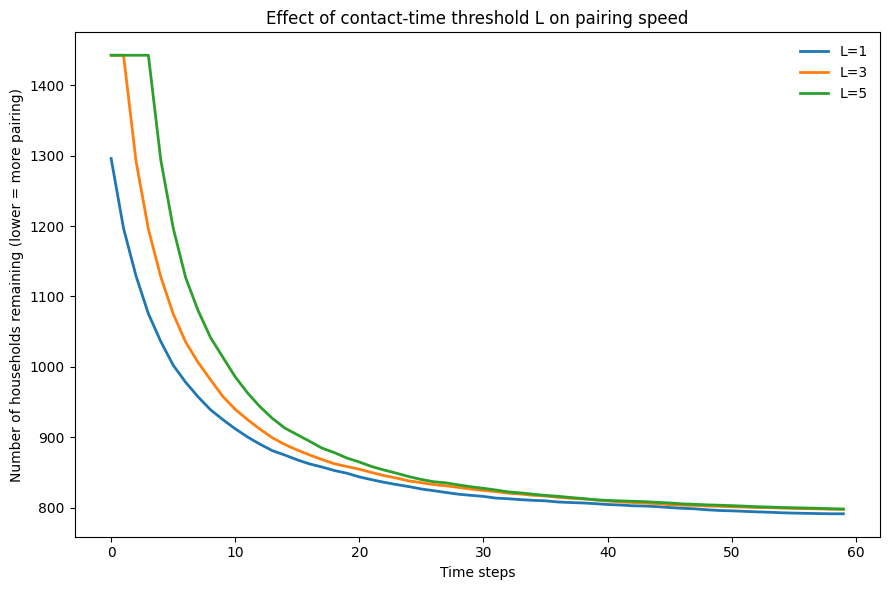

In [13]:
L_values = [1, 3, 5]
seeds_L = range(10)
n_steps_L = 60   # 效果集中在前40步左右，跑到60步就已经能看出全貌，不用跑到150

household_curves = {}

for L in L_values:
    all_runs = []
    for seed in seeds_L:
        np.random.seed(seed)
        g = ExtendedSchelling(n=40, p=0.4, m=0.05, L=L, q=0.70)
        curve = []
        for t in range(n_steps_L):
            out = g.step()
            curve.append(out['n_households'])
        all_runs.append(curve)
    household_curves[L] = np.mean(all_runs, axis=0)
    print(f"L={L}: households remaining after {n_steps_L} steps (avg of {len(seeds_L)} seeds) "
          f"= {household_curves[L][-1]:.1f}")

plt.figure(figsize=(9, 6))
for L in L_values:
    plt.plot(household_curves[L], label=f"L={L}")

decorate(title='Effect of contact-time threshold L on pairing speed',
         xlabel='Time steps',
         ylabel='Number of households remaining (lower = more pairing)')